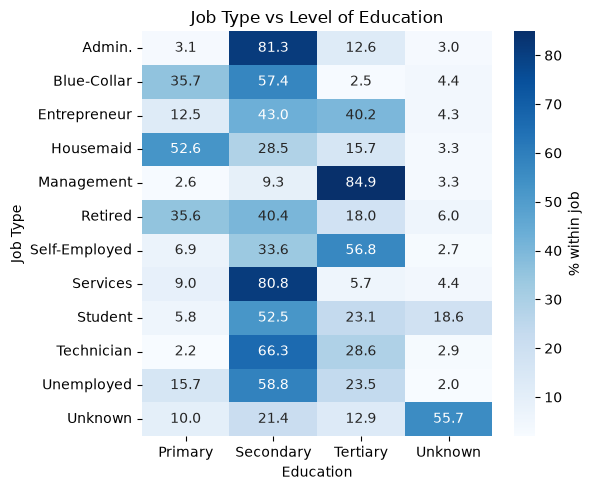

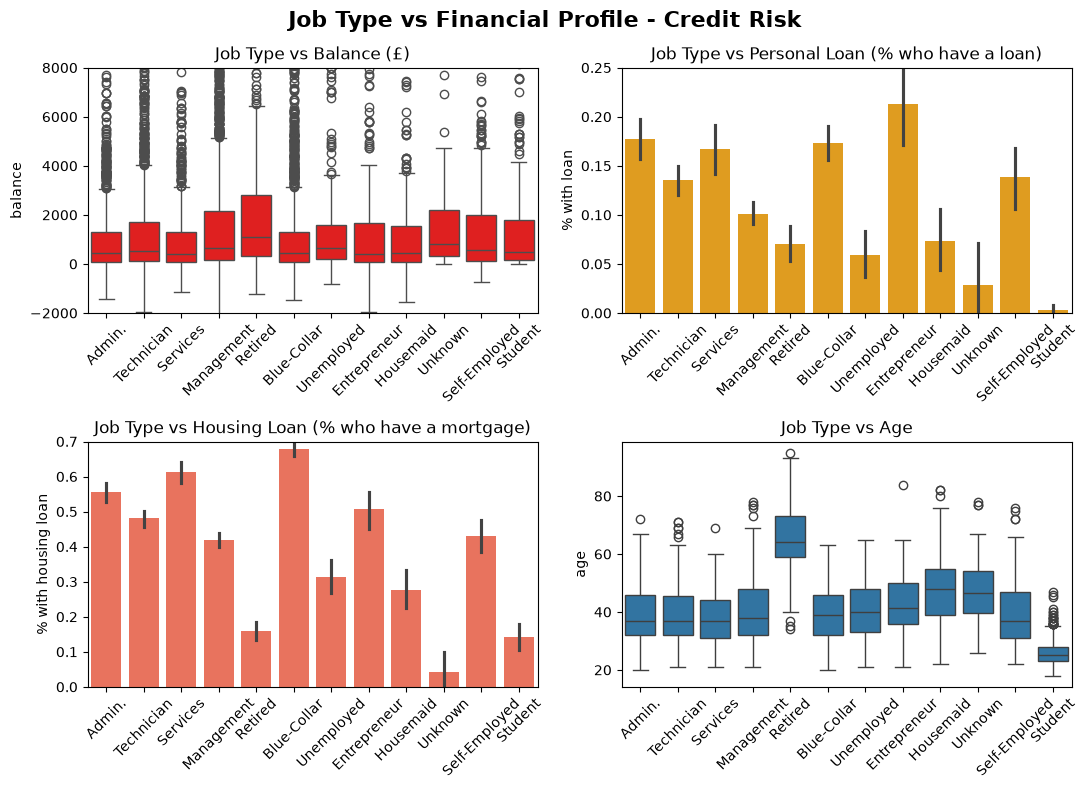

Max balance: 81204
Min balance: -6847
AVerage 1528.5385235620856


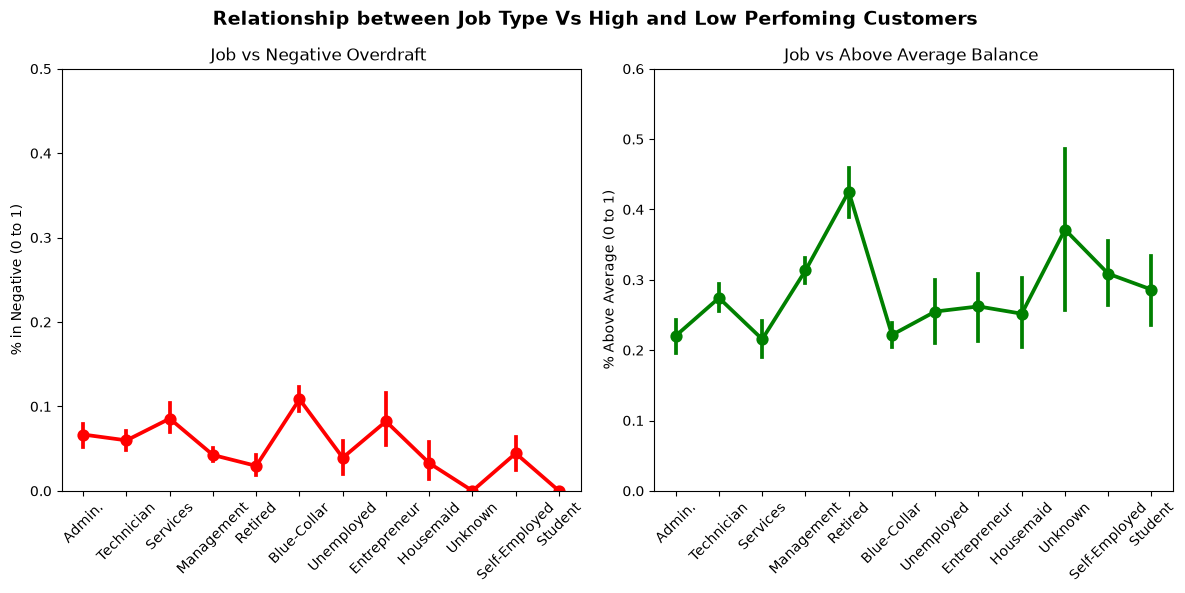

<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   age           11162 non-null  int64
 1   job           11162 non-null  str  
 2   education     11162 non-null  str  
 3   balance       11162 non-null  int64
 4   housing       11162 non-null  str  
 5   loan          11162 non-null  str  
 6   campaign      11162 non-null  int64
 7   pdays         11162 non-null  int64
 8   deposit       11162 non-null  str  
 9   deposit_yes   11162 non-null  int64
 10  loan_yes      11162 non-null  int64
 11  housing_yes   11162 non-null  int64
 12  is_negative   11162 non-null  int64
 13  is_above_avg  11162 non-null  int64
dtypes: int64(9), str(5)
memory usage: 1.2 MB


In [123]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("bank.csv")
#print(data.head())
df=data.copy()
#df.info()
df['deposit_yes'] = (df['deposit'] == 'yes').astype(int)# make a new column for depsoit_yes
df['loan_yes'] = (df['loan'] == 'yes').astype(int) #to be used in the grapgh
df['housing_yes'] = (df['housing'] == 'yes').astype(int)#to be used in the graph
df['is_negative'] = (df['balance'] < 0).astype(int) #to be used in the graph
df.isnull().sum()# checking null df['education'].isnull(), df=df.dropna(subset=['deposit']), df['balance'] = df['balance'].fillna(df['balance'].median())
df[df.duplicated()] # checking duplicate , df['education'] = df['education'].fillna('unknown')
df=df.drop_duplicates()#df = df.drop_duplicates(subset=['balance'], keep='first')
df.columns.tolist()
df=df.drop(columns=['marital','contact','default','day','month','previous','poutcome','duration'])
df['job']=df['job'].str.strip().str.title()
df['education']=df['education'].str.strip().str.title()
df.head(15)
df['job'].unique()
df.head()
df['education'].unique()
df.head()
# Make a table: job vs education, as percentages
job_edu = pd.crosstab(df['job'], df['education'], normalize='index') * 100
job_edu = job_edu.round(1)
plt.figure(figsize=(6, 5))

# Draw heatmap
sns.heatmap(job_edu,
            annot=True,      # To Show the numbers inside each cell
            fmt='.1f',       # 1 decimal place
            cmap='Blues',    
            cbar_kws={'label': '% within job'})

plt.title('Job Type vs Level of Education')
plt.xlabel('Education')
plt.ylabel('Job Type')
plt.tight_layout()
plt.show()

#Now we cross validate the different job category with customer income and financial profile

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
fig.suptitle('Job Type vs Financial Profile - Credit Risk', fontsize=16, fontweight='bold')

# Job vs Account Balance
sns.boxplot(data=df, x='job', y='balance',  ax=ax[0, 0],color = "red")
ax[0, 0].set_title('Job Type vs Balance (£)')
ax[0, 0].set_ylim(-2000, 8000)  # Zoom in, otherwise one rich person squashes everything
ax[0, 0].tick_params(axis='x', rotation=45)
ax[0, 0].set_xlabel('')

# Job vs Loan
# % of Job category who have a loan
sns.barplot(data=df, x='job', y='loan_yes', ax=ax[0, 1], color = 'orange')
ax[0, 1].set_title('Job Type vs Personal Loan (% who have a loan)')
ax[0, 1].set_ylim(0, 0.25)
ax[0, 1].tick_params(axis='x', rotation=45)
ax[0, 1].set_xlabel('')
ax[0, 1].set_ylabel('% with loan')

# Job vs Mortgage 
sns.barplot(data=df, x='job', y='housing_yes', ax=ax[1, 0], color = 'tomato')
ax[1, 0].set_title('Job Type vs Housing Loan (% who have a mortgage)')
ax[1, 0].set_ylim(0, 0.7)
ax[1, 0].tick_params(axis='x', rotation=45)
ax[1, 0].set_xlabel('')
ax[1, 0].set_ylabel('% with housing loan')

# Job vs Age 
sns.boxplot(data=df, x='job', y='age', ax=ax[1, 1])
ax[1, 1].set_title('Job Type vs Age')
ax[1, 1].tick_params(axis='x', rotation=45)
ax[1, 1].set_xlabel('')

plt.tight_layout()
plt.show()
# Now we are checking the Top Perfoming Customers and the Customer deep in Overdraft for flagging
print("Max balance:", df['balance'].max())
print("Min balance:", df['balance'].min())
print("AVerage",df['balance'].mean())
avg_balance = df['balance'].mean()
df['is_above_avg'] = (df['balance'] > avg_balance).astype(int)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
fig.suptitle('Relationship between Job Type Vs High and Low Perfoming Customers', fontsize=14, fontweight='bold')

#  Job vs Negative Overdraft
sns.pointplot(data=df, x='job', y='is_negative', ax=ax[0],color='red')
ax[0].set_title('Job vs Negative Overdraft ')
ax[0].set_ylabel('% in Negative (0 to 1)')
ax[0].set_ylim(0, 0.5)
ax[0].tick_params(axis='x', rotation=45)
ax[0].set_xlabel('')

# Job vs Above Average 
sns.pointplot(data=df, x='job', y='is_above_avg', ax=ax[1],color='green')
ax[1].set_title('Job vs Above Average Balance ')
ax[1].set_ylabel('% Above Average (0 to 1)')
ax[1].set_ylim(0, 0.6)
ax[1].tick_params(axis='x', rotation=45)
ax[1].set_xlabel('')

plt.tight_layout()
plt.show()

df.info()